In [1]:
%pip -q install sentencepiece sacrebleu pandas scikit-learn matplotlib transformers sacremoses

In [2]:
import copy
import csv
import random
import re
import tempfile
import time
import unicodedata
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import sentencepiece as spm
import torch
import torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
if DEVICE.type != 'cuda':
    print('WARNING: LSTM training will be much slower without a GPU.')

Device: cuda


In [3]:
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip'
ZIP_PATH = Path('fra-eng.zip')
EXTRACT_DIR = Path('data_raw')

if not ZIP_PATH.exists():
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
EXTRACT_DIR.mkdir(exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall(EXTRACT_DIR)

text_files = list(EXTRACT_DIR.rglob('fra.txt'))
assert text_files, 'Could not find fra.txt in the archive.'

pairs = pd.read_csv(
    text_files[0], sep='\t', header=None, usecols=[0, 1],
    names=['en', 'fr'], quoting=csv.QUOTE_NONE, encoding='utf-8'
)
rows_before = len(pairs)
pairs = pairs.dropna(subset=['en', 'fr']).copy()
pairs['en'] = pairs['en'].str.strip()
pairs['fr'] = pairs['fr'].str.strip()
pairs['en_words'] = pairs['en'].str.split().str.len()
pairs = pairs[(pairs['en'] != '') & (pairs['fr'] != '')]
pairs = pairs.drop_duplicates(subset=['en', 'fr'])
pairs = pairs[pairs['en_words'] <= 15]
pairs = pairs.reset_index(drop=True)
print('Raw sentence pairs:', rows_before)
print('Cleaned sentence pairs:', len(pairs))
display(pairs[['en', 'fr']].head())

Raw sentence pairs: 167130
Cleaned sentence pairs: 166340


,en,fr
0,Go.,Va !
1,Hi.,Salut !
2,Run!,Cours !
3,Run!,Courez !
4,Who?,Qui ?


In [4]:
def normalize_text(text):
    text = unicodedata.normalize('NFKC', str(text))
    text = text.casefold()
    return re.sub(r'\s+', ' ', text).strip()

def loose_normalize(text):
    text = normalize_text(text)
    text = re.sub(r'[\W_]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

pairs['en_key'] = pairs['en'].apply(normalize_text)
pairs['fr_key'] = pairs['fr'].apply(normalize_text)
pairs['en_loose'] = pairs['en'].apply(loose_normalize)
pairs['fr_loose'] = pairs['fr'].apply(loose_normalize)

parent = list(range(len(pairs)))
size = [1] * len(pairs)

def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

def union(a, b):
    root_a, root_b = find(a), find(b)
    if root_a == root_b:
        return
    if size[root_a] < size[root_b]:
        root_a, root_b = root_b, root_a
    parent[root_b] = root_a
    size[root_a] += size[root_b]

seen = {}
for i, (english, french) in enumerate(zip(pairs['en_loose'], pairs['fr_loose'])):
    for key in [('en', english), ('fr', french)]:
        if key in seen:
            union(i, seen[key])
        else:
            seen[key] = i

pairs['group_id'] = [find(i) for i in range(len(pairs))]
first_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, remaining_idx = next(first_split.split(pairs, groups=pairs['group_id']))
train_pairs = pairs.iloc[train_idx].reset_index(drop=True)
remaining_pairs = pairs.iloc[remaining_idx].reset_index(drop=True)
second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(second_split.split(
    remaining_pairs, groups=remaining_pairs['group_id']))
val_pairs = remaining_pairs.iloc[val_idx].reset_index(drop=True)
test_pairs = remaining_pairs.iloc[test_idx].reset_index(drop=True)

for left, right in [(train_pairs, val_pairs), (train_pairs, test_pairs), (val_pairs, test_pairs)]:
    for column in ['en_key', 'fr_key', 'en_loose', 'fr_loose', 'group_id']:
        assert not set(left[column]) & set(right[column]), f'Leakage detected in {column}'

print('Training pairs:', len(train_pairs))
print('Validation pairs:', len(val_pairs))
print('Test pairs:', len(test_pairs))
print('Overlap checks passed.')

Training pairs: 133017
Validation pairs: 16616
Test pairs: 16707
Overlap checks passed.


In [5]:
validation_df = val_pairs.drop_duplicates(subset='en_key').sample(
    n=min(500, val_pairs['en_key'].nunique()), random_state=42
).copy().reset_index(drop=True)

monitor_pool = val_pairs[~val_pairs['group_id'].isin(validation_df['group_id'])]
monitor_df = monitor_pool.drop_duplicates(subset='en_key').sample(
    n=min(1000, monitor_pool['en_key'].nunique()), random_state=43
).copy().reset_index(drop=True)

assert not set(monitor_df['en_key']) & set(validation_df['en_key'])
assert not set(monitor_df['group_id']) & set(validation_df['group_id'])
assert not set(train_pairs['group_id']) & set(validation_df['group_id'])
print('LSTM training-monitor sentences:', len(monitor_df))
print('Final comparison sentences:', len(validation_df))
display(validation_df[['en', 'fr']].head())

LSTM training-monitor sentences: 1000
Final comparison sentences: 500


,en,fr
0,Look up the words in your dictionary.,Cherchez les mots dans votre dictionnaire.
1,I arrived at the station ten minutes late.,Je suis arrivé à la gare dix minutes en retard.
2,I don't have the authority to order that.,Je ne dispose pas de l'autorité nécessaire pou...
3,We exchanged phone numbers at the end of the g...,Nous avons échangé nos numéros de téléphone à ...
4,"If that guitar were not so expensive, I could ...","Si cette guitare n'était pas si chère, je pour..."


In [6]:
TRAIN_LIMIT = 50000      # Change to len(train_pairs) for full-corpus training
EPOCHS = 5
PATIENCE = 2
BATCH_SIZE = 64
MAX_LEN = 48
VOCAB_SIZE = 6000
EMBED_DIM = 256
HIDDEN_DIM = 256
LEARNING_RATE = 0.001

train_df = train_pairs.sample(
    n=min(TRAIN_LIMIT, len(train_pairs)), random_state=SEED
).reset_index(drop=True)

print('Selected training pairs:', len(train_df))
print('Training monitor:', len(monitor_df))
print('Fixed comparison sample:', len(validation_df))

Selected training pairs: 50000
Training monitor: 1000
Fixed comparison sample: 500


In [7]:
with tempfile.TemporaryDirectory() as folder:
    folder = Path(folder)
    en_path, fr_path = folder / 'train.en', folder / 'train.fr'
    en_path.write_text('\n'.join(train_df['en'].tolist()), encoding='utf-8')
    fr_path.write_text('\n'.join(train_df['fr'].tolist()), encoding='utf-8')

    for lang, path in [('en', en_path), ('fr', fr_path)]:
        spm.SentencePieceTrainer.train(
            input=str(path),
            model_prefix=str(folder / lang),
            vocab_size=VOCAB_SIZE,
            model_type='bpe',
            character_coverage=1.0,
            hard_vocab_limit=False,
            pad_id=0, unk_id=1, bos_id=2, eos_id=3,
        )
    en_sp = spm.SentencePieceProcessor(model_file=str(folder / 'en.model'))
    fr_sp = spm.SentencePieceProcessor(model_file=str(folder / 'fr.model'))

PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
assert en_sp.pad_id() == fr_sp.pad_id() == PAD_ID
assert en_sp.eos_id() == fr_sp.eos_id() == EOS_ID
print('English vocabulary:', en_sp.vocab_size())
print('French vocabulary:', fr_sp.vocab_size())
print('Tokenized example:', en_sp.encode('I love French.', out_type=str))

English vocabulary: 6000
French vocabulary: 6000
Tokenized example: ['▁I', '▁love', '▁French', '.']


In [8]:
def encode_english(text):
    return en_sp.encode(str(text), out_type=int)[:MAX_LEN - 1] + [EOS_ID]

def encode_french(text):
    return [BOS_ID] + fr_sp.encode(str(text), out_type=int)[:MAX_LEN - 2] + [EOS_ID]

class TranslationDataset(Dataset):
    def __init__(self, frame):
        self.sources = [encode_english(x) for x in frame['en']]
        self.targets = [encode_french(x) for x in frame['fr']]

    def __len__(self):
        return len(self.sources)

    def __getitem__(self, index):
        return (torch.tensor(self.sources[index], dtype=torch.long),
                torch.tensor(self.targets[index], dtype=torch.long))

def collate_translation(batch):
    sources, targets = zip(*batch)
    return (pad_sequence(sources, batch_first=True, padding_value=PAD_ID),
            pad_sequence(targets, batch_first=True, padding_value=PAD_ID))

train_loader = DataLoader(
    TranslationDataset(train_df), batch_size=BATCH_SIZE, shuffle=True,
    collate_fn=collate_translation, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
monitor_loader = DataLoader(
    TranslationDataset(monitor_df), batch_size=BATCH_SIZE, shuffle=False,
    collate_fn=collate_translation, num_workers=0
)

sample_src, sample_tgt = next(iter(train_loader))
print('Source batch shape:', tuple(sample_src.shape))
print('French target shape:', tuple(sample_tgt.shape))

Source batch shape: (64, 20)
French target shape: (64, 26)


In [9]:
class AttentionLSTMTranslator(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, embed_dim=256, hidden_dim=256):
        super().__init__()
        assert hidden_dim % 2 == 0
        assert hidden_dim % 4 == 0
        self.src_embedding = nn.Embedding(src_vocab, embed_dim, padding_idx=PAD_ID)
        self.encoder = nn.LSTM(
            embed_dim, hidden_dim // 2, batch_first=True, bidirectional=True
        )
        self.init_h = nn.Linear(hidden_dim, hidden_dim)
        self.init_c = nn.Linear(hidden_dim, hidden_dim)
        self.tgt_embedding = nn.Embedding(tgt_vocab, embed_dim, padding_idx=PAD_ID)
        self.decoder = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.attention = nn.MultiheadAttention(
            embed_dim=hidden_dim, num_heads=4, batch_first=True
        )
        self.output = nn.Linear(hidden_dim * 2, tgt_vocab)

    def encode(self, src):
        source_is_pad = src.eq(PAD_ID)
        lengths = src.ne(PAD_ID).sum(dim=1).cpu()
        embedded = self.src_embedding(src)
        packed = pack_padded_sequence(
            embedded, lengths, batch_first=True, enforce_sorted=False
        )
        packed_outputs, (hidden, cell) = self.encoder(packed)
        encoder_outputs, _ = pad_packed_sequence(
            packed_outputs, batch_first=True, total_length=src.size(1)
        )
        decoder_hidden = torch.tanh(self.init_h(
            torch.cat([hidden[-2], hidden[-1]], dim=-1)
        )).unsqueeze(0)
        decoder_cell = torch.tanh(self.init_c(
            torch.cat([cell[-2], cell[-1]], dim=-1)
        )).unsqueeze(0)
        return encoder_outputs, (decoder_hidden, decoder_cell), source_is_pad

    def decode_step_or_sequence(self, target_inputs, states, encoder_outputs, source_is_pad):
        target_embeddings = self.tgt_embedding(target_inputs)
        decoder_outputs, new_states = self.decoder(target_embeddings, states)
        context, _ = self.attention(
            query=decoder_outputs, key=encoder_outputs, value=encoder_outputs,
            key_padding_mask=source_is_pad, need_weights=False
        )
        logits = self.output(torch.cat([decoder_outputs, context], dim=-1))
        return logits, new_states

    def forward(self, src, target_inputs):
        encoder_outputs, states, source_is_pad = self.encode(src)
        logits, _ = self.decode_step_or_sequence(
            target_inputs, states, encoder_outputs, source_is_pad
        )
        return logits

model = AttentionLSTMTranslator(
    src_vocab=en_sp.vocab_size(), tgt_vocab=fr_sp.vocab_size(),
    embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM
).to(DEVICE)
print('LSTM parameters:', f'{sum(p.numel() for p in model.parameters()):,}')

# Basic shape check, before spending time on training.
with torch.no_grad():
    demo_logits = model(sample_src[:2].to(DEVICE), sample_tgt[:2, :-1].to(DEVICE))
assert demo_logits.shape == (2, sample_tgt.size(1) - 1, fr_sp.vocab_size())
print('Forward-pass shape check passed:', tuple(demo_logits.shape))

LSTM parameters: 7,466,352
Forward-pass shape check passed: (2, 25, 6000)


In [10]:
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD_ID)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

@torch.no_grad()
def average_teacher_forced_loss(data_loader):
    model.eval()
    weighted_loss = 0.0
    token_count = 0
    for source, target in data_loader:
        source, target = source.to(DEVICE), target.to(DEVICE)
        logits = model(source, target[:, :-1])
        gold = target[:, 1:]
        loss = loss_fn(logits.reshape(-1, logits.size(-1)), gold.reshape(-1))
        n_tokens = gold.ne(PAD_ID).sum().item()
        weighted_loss += loss.item() * n_tokens
        token_count += n_tokens
    return weighted_loss / max(token_count, 1)

history = []
best_loss = float('inf')
best_state = None
best_epoch = None
stale_epochs = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    total_tokens = 0
    start = time.perf_counter()
    for batch_idx, (source, target) in enumerate(train_loader, start=1):
        source, target = source.to(DEVICE), target.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(source, target[:, :-1])
        gold = target[:, 1:]
        loss = loss_fn(logits.reshape(-1, logits.size(-1)), gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        n_tokens = gold.ne(PAD_ID).sum().item()
        total_loss += loss.item() * n_tokens
        total_tokens += n_tokens
        if batch_idx % 200 == 0:
            print(f'Epoch {epoch}: {batch_idx}/{len(train_loader)} batches')

    train_loss = total_loss / max(total_tokens, 1)
    monitor_loss = average_teacher_forced_loss(monitor_loader)
    elapsed = time.perf_counter() - start
    history.append({'epoch': epoch, 'train_loss': train_loss,
                    'monitor_loss': monitor_loss, 'seconds': elapsed})
    print(f'Epoch {epoch}: train={train_loss:.4f}, '
          f'monitor={monitor_loss:.4f}, time={elapsed:.1f}s')

    if monitor_loss < best_loss - 1e-4:
        best_loss = monitor_loss
        best_epoch = epoch
        best_state = {key: value.detach().cpu().clone()
                      for key, value in model.state_dict().items()}
        stale_epochs = 0
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print('Early stopping triggered.')
            break

assert best_state is not None
model.load_state_dict(best_state)
model.eval()
print('Selected epoch:', best_epoch)
print('Best monitoring loss:', round(best_loss, 4))
display(pd.DataFrame(history))

Epoch 1: 200/782 batches
Epoch 1: 400/782 batches
Epoch 1: 600/782 batches
Epoch 1: train=3.3145, monitor=2.3729, time=18.4s
Epoch 2: 200/782 batches
Epoch 2: 400/782 batches
Epoch 2: 600/782 batches
Epoch 2: train=1.8107, monitor=1.9128, time=15.0s
Epoch 3: 200/782 batches
Epoch 3: 400/782 batches
Epoch 3: 600/782 batches
Epoch 3: train=1.3092, monitor=1.7792, time=14.3s
Epoch 4: 200/782 batches
Epoch 4: 400/782 batches
Epoch 4: 600/782 batches
Epoch 4: train=1.0170, monitor=1.7374, time=14.3s
Epoch 5: 200/782 batches
Epoch 5: 400/782 batches
Epoch 5: 600/782 batches
Epoch 5: train=0.8113, monitor=1.7569, time=15.5s
Selected epoch: 4
Best monitoring loss: 1.7374


,epoch,train_loss,monitor_loss,seconds
0,1,3.314504,2.372943,18.445172
1,2,1.810668,1.912779,14.963795
2,3,1.309184,1.779218,14.329661
3,4,1.017019,1.737388,14.341360
4,5,0.811290,1.756918,15.468128


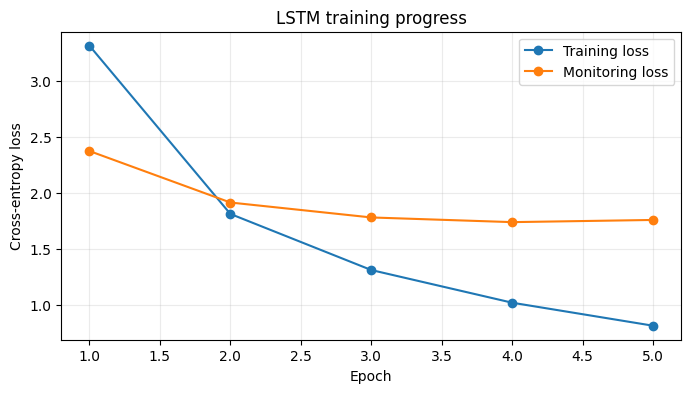

In [11]:
history_df = pd.DataFrame(history)
plt.figure(figsize=(8, 4))
plt.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Training loss')
plt.plot(history_df['epoch'], history_df['monitor_loss'], marker='o', label='Monitoring loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.title('LSTM training progress')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [12]:
@torch.inference_mode()
def lstm_translate(sentences, batch_size=32):
    model.eval()
    translations = []
    for start in range(0, len(sentences), batch_size):
        texts = sentences[start:start + batch_size]
        source_tokens = [torch.tensor(encode_english(x), dtype=torch.long) for x in texts]
        source = pad_sequence(source_tokens, batch_first=True,
                              padding_value=PAD_ID).to(DEVICE)
        encoder_outputs, states, source_is_pad = model.encode(source)
        previous = torch.full((len(texts), 1), BOS_ID, dtype=torch.long, device=DEVICE)
        completed = torch.zeros(len(texts), dtype=torch.bool, device=DEVICE)
        sequences = [[] for _ in texts]

        for _ in range(MAX_LEN - 1):
            logits, states = model.decode_step_or_sequence(
                previous, states, encoder_outputs, source_is_pad
            )
            next_ids = logits[:, -1, :].argmax(dim=-1)
            next_ids = torch.where(completed, torch.full_like(next_ids, EOS_ID), next_ids)
            for index, token in enumerate(next_ids.tolist()):
                if not completed[index].item() and token != EOS_ID:
                    sequences[index].append(token)
            completed = completed | next_ids.eq(EOS_ID)
            previous = next_ids.unsqueeze(1)
            if bool(completed.all().item()):
                break

        translations.extend([fr_sp.decode(ids) for ids in sequences])
    return translations

examples = ['I am happy.', 'Where is the station?', 'She reads a book.']
for sentence, translation in zip(examples, lstm_translate(examples)):
    print('EN:', sentence)
    print('FR (LSTM):', translation)
    print('---')

EN: I am happy.
FR (LSTM): Je suis heureux.
---
EN: Where is the station?
FR (LSTM): Où est la gare ?
---
EN: She reads a book.
FR (LSTM): Elle lit un livre.
---


In [13]:
PREDICTIONS_FILE = (
    'https://raw.githubusercontent.com/MeouchyCharbel/'
    'Neural-Machine-Translation/main/results/validation_predictions.csv'
)
prior_predictions = pd.read_csv(PREDICTIONS_FILE, keep_default_na=False)
required = {'en', 'fr', 'dictionary_translation',
            'retrieval_translation', 'transformer_greedy'}
assert required.issubset(prior_predictions.columns), 'Saved Notebook 02 predictions are missing columns.'
assert len(prior_predictions) == len(validation_df), 'Evaluation sample sizes differ.'
assert prior_predictions['en'].tolist() == validation_df['en'].tolist(), (
    'English evaluation sentences differ from Notebook 02; check dataset splitting.'
)
assert prior_predictions['fr'].tolist() == validation_df['fr'].tolist(), (
    'Reference translations differ from Notebook 02; do not compare scores.'
)
print('Verified:', len(validation_df), 'identical validation examples and references.')

Verified: 500 identical validation examples and references.


In [14]:
english = validation_df['en'].tolist()
references = validation_df['fr'].tolist()
if DEVICE.type == 'cuda':
    torch.cuda.synchronize()
start = time.perf_counter()
lstm_predictions = lstm_translate(english)
if DEVICE.type == 'cuda':
    torch.cuda.synchronize()
lstm_inference_seconds = time.perf_counter() - start

method_predictions = {
    'Dictionary baseline': prior_predictions['dictionary_translation'].tolist(),
    'TF-IDF retrieval': prior_predictions['retrieval_translation'].tolist(),
    'Pretrained Transformer (greedy)': prior_predictions['transformer_greedy'].tolist(),
    'LSTM + attention (trained here)': lstm_predictions,
}
metrics = []
for name, predictions in method_predictions.items():
    assert len(predictions) == len(references)
    metrics.append({
        'Model': name,
        'BLEU': round(sacrebleu.corpus_bleu(predictions, [references]).score, 2),
        'chrF': round(sacrebleu.corpus_chrf(predictions, [references]).score, 2),
        'Evaluation sentences': len(references)
    })
metrics_df = pd.DataFrame(metrics)
print('LSTM inference time on', DEVICE, ':', round(lstm_inference_seconds, 2), 's')
print('Do NOT compare this latency with Notebook 02 CPU timings unless hardware matches.')
display(metrics_df)

LSTM inference time on cuda : 0.59 s
Do NOT compare this latency with Notebook 02 CPU timings unless hardware matches.


,Model,BLEU,chrF,Evaluation sentences
0,Dictionary baseline,0.66,16.14,500
1,TF-IDF retrieval,18.39,37.74,500
2,Pretrained Transformer (greedy),55.11,70.40,500
3,LSTM + attention (trained here),28.55,50.39,500


In [15]:
comparison_df = validation_df[['en', 'fr']].copy()
comparison_df['Dictionary'] = method_predictions['Dictionary baseline']
comparison_df['TF-IDF'] = method_predictions['TF-IDF retrieval']
comparison_df['Transformer'] = method_predictions['Pretrained Transformer (greedy)']
comparison_df['LSTM'] = lstm_predictions
comparison_df['LSTM sentence chrF'] = [
    round(sacrebleu.sentence_chrf(pred, [ref]).score, 2)
    for pred, ref in zip(lstm_predictions, references)
]

print('Random translation examples:')
display(comparison_df.sample(n=10, random_state=42))
print('Examples with lowest LSTM sentence chrF:')
display(comparison_df.nsmallest(10, 'LSTM sentence chrF'))

Random translation examples:


,en,fr,Dictionary,TF-IDF,Transformer,LSTM,LSTM sentence chrF
361,I made a list of things I needed to bring with...,J'ai dressé une liste des choses qu'il me fall...,Je made un list of things je needed to bring w...,J'ai dressé une liste des choses qu'il me fall...,J'ai fait une liste de choses que j'avais beso...,Je dressai une liste des choses dont je voulai...,41.70
73,Tom is worried about Mary's safety.,Tom s'inquiète pour la sécurité de Mary.,Tom est worried about mary ' s safety.,Tom s'inquiète pour ses enfants.,Tom s'inquiète pour la sécurité de Mary.,Tom s'en inquiète à Mary.,35.94
374,We discussed the problem for a long time.,Nous avons discuté du problème depuis longtemp...,We discussed la problem for un long time.,Nous avons débattu sur le problème.,Nous avons discuté du problème pendant longtemps.,Nous discutâmes du problème pour une longue pé...,40.37
155,Let's spread the map on the table and talk it ...,Étalons la carte sur la table et discutons.,Let ' s spread la map on la table and talk it ...,Déplions la carte sur la table et discutons-en.,Disons la carte sur la table et parlons-en.,Permettez la carte sur la table et parlons.,57.21
104,I will get in touch with you.,Je te contacterai.,Je will get in touch with you.,Nous vous recontacterons.,Je vais vous contacter.,Je me suis tou toubé à vous.,8.78
394,They all laughed at his error.,Tous ont ri à son erreur.,They all laughed at his error.,Ils ont ri de leur erreur.,Ils se sont tous moqués de son erreur.,Ils ont tous moquée de son erreur.,50.91
377,"Push the button, please.",Veuillez appuyer sur le bouton.,"Push la button, please.",Puis-je appuyer sur le bouton ?,"Appuyez sur le bouton, s'il vous plaît.",Cache le bouton s'il vous plaît.,28.27
124,Experience is the best teacher.,Expérience passe science.,Experience est la best teacher.,Je suis le meilleur.,L'expérience est le meilleur professeur.,Le temps a l'air de l'institutrice.,12.44
68,Do your homework right away.,Fais tes devoirs immédiatement.,Do your homework right away.,Fais tes devoirs.,Fais tes devoirs tout de suite.,Fais de vos devoirs immédiatement.,81.86
450,I've done the right thing.,J'ai fait le bon choix.,Je ' ve done la right thing.,J'ai fait ce qu'il fallait faire.,J'ai fait ce qu'il fallait.,J'ai fait ce qu'il fallait.,35.33


Examples with lowest LSTM sentence chrF:


,en,fr,Dictionary,TF-IDF,Transformer,LSTM,LSTM sentence chrF
76,Here we are.,On y est.,Here we are.,Nous voici donc de nouveau au même point.,Nous y voilà.,Voici.,2.45
6,You have to go.,Il faut que tu t'en ailles.,You have to go.,Je dois y aller.,Il faut que tu partes.,Vous devez partir.,6.41
54,Her attitude disgusts me.,Son attitude me dégoûte.,Her attitude disgusts me.,C'est la bonne attitude.,Son attitude me dégoûte.,Sa capacité m'a fait m'un.,8.69
104,I will get in touch with you.,Je te contacterai.,Je will get in touch with you.,Nous vous recontacterons.,Je vais vous contacter.,Je me suis tou toubé à vous.,8.78
277,Your hair's beautiful.,Tes cheveux sont beaux.,Your hair ' s beautiful.,Te teins-tu les cheveux ?,Tes cheveux sont beaux.,Ton réal sonne.,9.17
8,I made sure of that.,Je m'en suis assuré.,Je made sure of that.,Nous en sommes tous certains.,J'en ai assuré.,J'ai fait sûre que ça.,9.69
218,He appeared from nowhere.,Il est apparu de nulle part.,He appeared from nowhere.,Il avait l'air honnête.,Il est apparu de nulle part.,Il s'est raséé.,9.73
420,I was discouraged.,On me dissuada.,Je was discouraged.,Je ne suis pas découragé.,J'étais découragé.,J'étais découragé.,9.76
39,I read an exciting story.,Je lus une histoire passionnante.,Je read an exciting story.,Producteur est un travail passionnant.,J'ai lu une histoire passionnante.,J'ai lu un sacrifiée.,10.64
453,Trade helps nations develop.,Le commerce aide les pays à se développer.,Trade helps nations develop.,Les deux nations ont de forts liens commerciaux.,Le commerce aide les nations à se développer.,Les voitures ont accueils ont été abondés.,10.93


In [16]:
RESULT_DIR = Path('results')
RESULT_DIR.mkdir(exist_ok=True)
metrics_path = RESULT_DIR / 'lstm_comparison_metrics.csv'
predictions_path = RESULT_DIR / 'lstm_comparison_predictions.csv'
metrics_df.to_csv(metrics_path, index=False)
comparison_df.to_csv(predictions_path, index=False)
print('Created:', metrics_path)
print('Created:', predictions_path)

# Optional: save the trained LSTM state and trained tokenizers if you need reuse.
# spm processors have serialized_model_proto() to preserve the exact training vocabulary.
checkpoint = {
    'model_state_dict': {k: v.cpu() for k, v in model.state_dict().items()},
    'english_sentencepiece_model': en_sp.serialized_model_proto(),
    'french_sentencepiece_model': fr_sp.serialized_model_proto(),
    'config': {'embed_dim': EMBED_DIM, 'hidden_dim': HIDDEN_DIM,
               'max_len': MAX_LEN, 'seed': SEED},
    'best_epoch': best_epoch,
    'best_monitor_loss': best_loss,
}
torch.save(checkpoint, 'lstm_attention_checkpoint.pt')
print('Created: lstm_attention_checkpoint.pt (do not commit large weights without checking size)')

Created: results/lstm_comparison_metrics.csv
Created: results/lstm_comparison_predictions.csv
Created: lstm_attention_checkpoint.pt (do not commit large weights without checking size)
